# Student Performance Analytics: Identifying Students at Risk

## 1. Project Overview

**Objective:** Investigate the factors associated with mathematics performance and evaluate whether machine learning can identify students at risk of academic failure.

Early identification of struggling students could help schools provide targeted academic support. However, predictions must be accurate, interpretable and available early enough to support meaningful intervention.

### Key Questions

1. Which student characteristics are associated with final mathematics performance?
2. Can students at risk of failure be identified using information available before academic grades are recorded?
3. How does predictive performance change when second-period mathematics grades become available?
4. Does increasing model complexity improve prediction accuracy?

### Dataset

This project uses the UCI Student Performance dataset, containing information about 395 secondary-school students studying mathematics in Portugal.

The dataset includes demographic characteristics, study habits, previous academic failures, attendance and academic grades.

### Tools and Techniques

- Python, Pandas and Matplotlib
- Exploratory Data Analysis (EDA)
- Correlation analysis
- Linear and logistic regression
- Random forest classification
- Cross-validation
- ROC-AUC, accuracy, precision and recall

### Project Outcome

The analysis explores the trade-off between early identification and predictive accuracy. It also demonstrates why simpler, interpretable models can sometimes perform as well as more complex alternatives.

The models are evaluated as exploratory research tools rather than validated systems for making decisions about individual students.

## 2. Data Loading and Initial Inspection

The dataset contains student demographic information, study habits, academic history and mathematics grades.

The data was imported using Pandas. Initial inspection was performed to understand the dataset's structure, identify variable types and check for potential data-quality issues.

The CSV file uses a semicolon (`;`) as its delimiter rather than a comma.

In [34]:
import pandas as pd


In [35]:
df = pd.read_csv("student-mat.csv", sep=";")

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was conducted to understand the distribution of mathematics grades, identify patterns in student performance and investigate relationships between academic outcomes and student characteristics.

The analysis focused on:

- The distribution of final mathematics grades (G3).
- Average grades and variation in student performance.
- Relationships between absences and final grades.
- Correlations between first-period (G1), second-period (G2) and final mathematics grades (G3).
- Previous academic failures and their association with final mathematics performance.

### Key Analytical Considerations

Correlation does not imply causation. Relationships identified in this analysis should be interpreted as associations rather than evidence that one variable directly influences another.

Potential data-quality issues, including students with zero final grades and zero recorded absences, were also investigated.

In [37]:
df[["G1", "G2", "G3"]].describe()


,G1,G2,G3
count,395.000000,395.000000,395.000000
mean,10.908861,10.713924,10.415190
std,3.319195,3.761505,4.581443
min,3.000000,0.000000,0.000000
25%,8.000000,9.000000,8.000000
50%,11.000000,11.000000,11.000000
75%,13.000000,13.000000,14.000000
max,19.000000,19.000000,20.000000


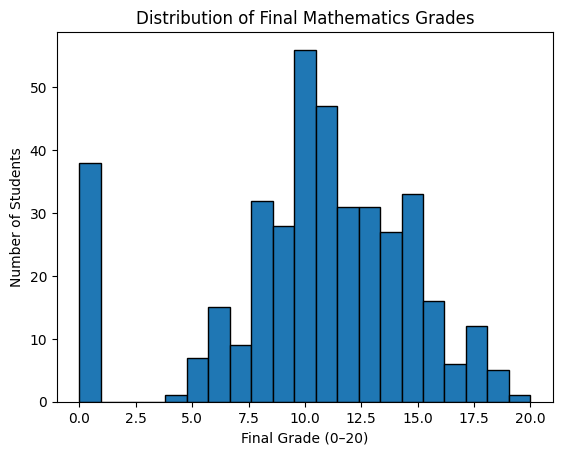

In [38]:
import matplotlib.pyplot as plt

plt.hist(df["G3"], bins=21, edgecolor="black")

plt.title("Distribution of Final Mathematics Grades")
plt.xlabel("Final Grade (0–20)")
plt.ylabel("Number of Students")

plt.show()


In [39]:
zero_students = df[df["G3"] == 0]

print("Number of students with a final grade of 0:", len(zero_students))

zero_students[["G1", "G2", "G3", "absences"]].head(10)

Number of students with a final grade of 0: 38


,G1,G2,G3,absences
128,7,4,0,0
130,12,0,0,0
131,8,0,0,0
134,9,0,0,0
135,11,0,0,0
136,10,0,0,0
137,4,0,0,0
140,7,9,0,0
144,5,0,0,0
146,6,7,0,0


In [40]:
df.groupby(df["G3"] == 0)[["absences", "G1", "G2"]].mean()

,absences,G1,G2
G3,,,
False,6.316527,11.268908,11.358543
True,0.000000,7.526316,4.657895


In [41]:
df.groupby("G3")["absences"].agg(["count", "mean", "min", "max"])

,count,mean,min,max
G3,,,,
0,38,0.000000,0,0
4,1,22.000000,22,22
5,7,11.428571,2,16
6,15,8.066667,0,26
7,9,6.777778,0,18
8,32,9.718750,0,56
9,28,10.142857,0,75
10,56,4.857143,0,19
11,47,7.510638,0,54


In [42]:
import pandas as pd

df = pd.read_csv("student-mat.csv", sep=";")

df.groupby("G3")["absences"].agg(["count", "mean", "min", "max"])

,count,mean,min,max
G3,,,,
0,38,0.000000,0,0
4,1,22.000000,22,22
5,7,11.428571,2,16
6,15,8.066667,0,26
7,9,6.777778,0,18
8,32,9.718750,0,56
9,28,10.142857,0,75
10,56,4.857143,0,19
11,47,7.510638,0,54


In [43]:
df[["absences", "G3"]].corr()

,absences,G3
absences,1.000000,0.034247
G3,0.034247,1.000000


In [44]:
df_nonzero = df[df["G3"] > 0]

df_nonzero[["absences", "G3"]].corr()

,absences,G3
absences,1.000000,-0.213129
G3,-0.213129,1.000000


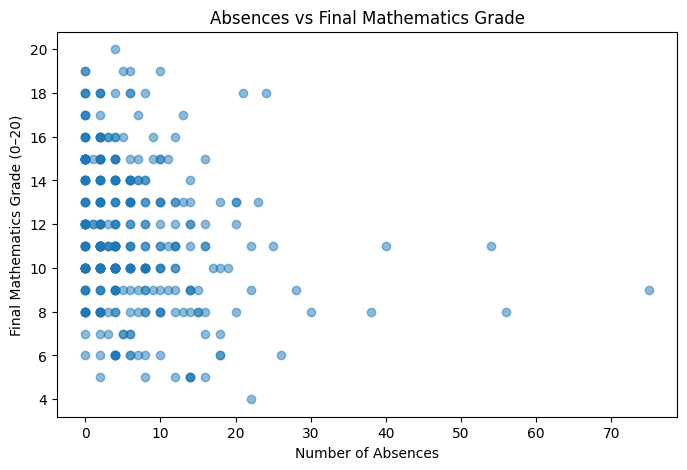

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df_nonzero["absences"],
    df_nonzero["G3"],
    alpha=0.5
)

plt.title("Absences vs Final Mathematics Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Mathematics Grade (0–20)")

plt.show()

In [46]:
df[["G1", "G2", "G3"]].corr()

,G1,G2,G3
G1,1.000000,0.852118,0.801468
G2,0.852118,1.000000,0.904868
G3,0.801468,0.904868,1.000000


In [47]:
correlations = df[["G1", "G2", "G3"]].corr()

print("G1 R-squared:", correlations.loc["G1", "G3"] ** 2)
print("G2 R-squared:", correlations.loc["G2", "G3"] ** 2)

G1 R-squared: 0.642350846052271
G2 R-squared: 0.8187860780042664


## 4. Predictive Modelling

### 4.1 Linear Regression: Predicting Final Mathematics Grades

Linear regression was used to investigate whether students' earlier mathematics grades could predict their final grades (G3).

The initial model used second-period mathematics grades (G2) as the predictor. A multiple linear regression model was subsequently developed using G1, G2 and absences.

Model performance was evaluated using:

- Mean Absolute Error (MAE)
- R-squared (R²)
- Train-test splitting
- Cross-validation

The objective was to compare predictive accuracy and determine whether adding more variables meaningfully improved performance.

**Important limitation:** Models using G1 or G2 cannot provide genuine beginning-of-year predictions because these grades are not available at that stage.

In [48]:
from sklearn.linear_model import LinearRegression

X = df[["G2"]]
y = df["G3"]

model = LinearRegression()
model.fit(X, y)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])
print("R-squared:", model.score(X, y))

Intercept: -1.3927582066452384
Coefficient: 1.1021123562440618
R-squared: 0.818786078004268


In [49]:
from sklearn.model_selection import train_test_split

X = df[["G2"]]
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training students:", len(X_train))
print("Testing students:", len(X_test))

Training students: 316
Testing students: 79


In [50]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict grades for the 79 test students
y_pred = model.predict(X_test)

# Evaluate predictions
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Test MAE:", round(mae, 3))
print("Test R-squared:", round(r2, 3))

Test MAE: 1.209
Test R-squared: 0.794


In [51]:
# Select additional predictors
X_multiple = df[["G1", "G2", "absences"]]

# Keep exactly the same training and testing students
X_train_multiple = X_multiple.loc[X_train.index]
X_test_multiple = X_multiple.loc[X_test.index]

# Train the multiple regression model
model_multiple = LinearRegression()
model_multiple.fit(X_train_multiple, y_train)

# Predict final grades
y_pred_multiple = model_multiple.predict(X_test_multiple)

# Evaluate
print("Multiple Regression MAE:",
      round(mean_absolute_error(y_test, y_pred_multiple), 3))

print("Multiple Regression R-squared:",
      round(r2_score(y_test, y_pred_multiple), 3))

Multiple Regression MAE: 1.311
Multiple Regression R-squared: 0.795


In [52]:
import pandas as pd

coefficients = pd.DataFrame({
    "Variable": X_train_multiple.columns,
    "Coefficient": model_multiple.coef_
})

print(coefficients)
print("Intercept:", model_multiple.intercept_)

   Variable  Coefficient
0        G1     0.162584
1        G2     0.994194
2  absences     0.038610
Intercept: -2.2697173416659684


In [53]:
df[["G1", "G2"]].corr()

,G1,G2
G1,1.000000,0.852118
G2,0.852118,1.000000


In [54]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import pandas as pd

X_vif = df[["G1", "G2", "absences"]]

# Include an intercept when calculating VIF
X_vif = add_constant(X_vif)

vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

print(vif)

   Variable       VIF
0     const  1.000000
1        G1  3.651242
2        G2  3.651420
3  absences  1.001067


In [55]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

cv_g2 = -cross_val_score(
    LinearRegression(),
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

cv_multiple = -cross_val_score(
    LinearRegression(),
    X_train_multiple,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

print("G2-only average MAE:", round(cv_g2.mean(), 3))
print("Multiple regression average MAE:", round(cv_multiple.mean(), 3))

G2-only average MAE: 1.136
Multiple regression average MAE: 1.155


In [56]:
# Create a binary target variable
df["pass"] = (df["G3"] >= 10).astype(int)

# Count students in each category
print(df["pass"].value_counts())

# Calculate percentages
print(df["pass"].value_counts(normalize=True) * 100)

pass
1    265
0    130
Name: count, dtype: int64
pass
1    67.088608
0    32.911392
Name: proportion, dtype: float64


In [57]:
import pandas as pd

df = pd.read_csv("student-mat.csv", sep=";")

print(df.shape)

(395, 33)


### 4.2 Classification: Predicting Mathematics Pass or Fail

Classification models were developed to predict whether students would pass or fail their final mathematics examination.

Students were classified using a passing threshold of 10 out of 20:

- **Pass (1):** Final grade of 10 or higher.
- **Fail (0):** Final grade below 10.

Two prediction approaches were investigated:

**Later-stage prediction:** Logistic regression using second-period mathematics grades (G2), which become available during the academic year.

**Early-warning prediction:** Logistic regression using student characteristics available before examination grades, including previous academic failures, study time and other background variables.

Model performance was assessed using accuracy, precision, recall, confusion matrices and ROC-AUC.

Particular attention was given to **failure recall**, as identifying students who may require additional academic support was the primary objective.

In [58]:
df["pass"] = (df["G3"] >= 10).astype(int)

print(df["pass"].value_counts())
print(df["pass"].value_counts(normalize=True) * 100)

pass
1    265
0    130
Name: count, dtype: int64
pass
1    67.088608
0    32.911392
Name: proportion, dtype: float64


In [59]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score

X = df[["G2"]]
y = df["pass"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

classifier = LogisticRegression()
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Fail recall:", round(recall_score(y_test, y_pred, pos_label=0), 3))

Accuracy: 0.873
Fail recall: 0.962


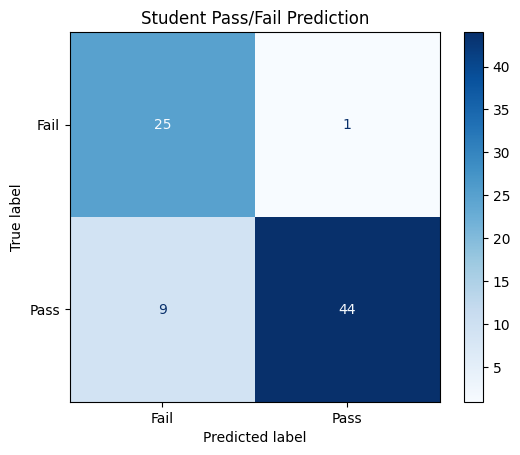

In [60]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fail", "Pass"]
)

display.plot(cmap="Blues")
plt.title("Student Pass/Fail Prediction")
plt.show()

In [61]:
# Predict probability of passing
pass_probabilities = classifier.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Pass_Probability": pass_probabilities
})

print(results.head(10).round(3))

   Actual  Predicted  Pass_Probability
0       1          1             0.995
1       0          0             0.087
2       1          1             0.995
3       1          1             0.966
4       1          1             1.000
5       1          1             0.999
6       1          1             1.000
7       0          0             0.388
8       1          1             0.808
9       1          1             1.000


In [62]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

# Change the passing threshold to 70%
new_predictions = (pass_probabilities >= 0.70).astype(int)

# Evaluate identification of failing students
print("Fail recall:",
      round(recall_score(y_test, new_predictions, pos_label=0), 3))

print("Fail precision:",
      round(precision_score(y_test, new_predictions, pos_label=0), 3))

print("Confusion matrix:")
print(confusion_matrix(y_test, new_predictions, labels=[0, 1]))

Fail recall: 0.962
Fail precision: 0.735
Confusion matrix:
[[25  1]
 [ 9 44]]


In [63]:
# Find students with passing probabilities between 50% and 70%
borderline = results[
    (results["Pass_Probability"] >= 0.50) &
    (results["Pass_Probability"] < 0.70)
]

print("Students between 50% and 70%:", len(borderline))
print(borderline)

Students between 50% and 70%: 0
Empty DataFrame
Columns: [Actual, Predicted, Pass_Probability]
Index: []


In [64]:
from sklearn.metrics import precision_score, recall_score

for threshold in [0.3, 0.5, 0.7, 0.8, 0.9]:
    predictions = (pass_probabilities >= threshold).astype(int)

    recall = recall_score(y_test, predictions, pos_label=0)
    precision = precision_score(
        y_test, predictions, pos_label=0, zero_division=0
    )

    print(
        f"Threshold: {threshold:.1f} | "
        f"Fail Recall: {recall:.3f} | "
        f"Fail Precision: {precision:.3f}"
    )

Threshold: 0.3 | Fail Recall: 0.692 | Fail Precision: 0.857
Threshold: 0.5 | Fail Recall: 0.962 | Fail Precision: 0.735
Threshold: 0.7 | Fail Recall: 0.962 | Fail Precision: 0.735
Threshold: 0.8 | Fail Recall: 0.962 | Fail Precision: 0.735
Threshold: 0.9 | Fail Recall: 1.000 | Fail Precision: 0.650


In [65]:
# Create a table of students ranked by estimated failure risk
risk_ranking = pd.DataFrame({
    "Actual": y_test.values,
    "G2": X_test["G2"].values,
    "Failure_Risk": 1 - pass_probabilities
})

# Rank from highest to lowest risk
risk_ranking = risk_ranking.sort_values(
    by="Failure_Risk",
    ascending=False
)

# Select the 30 highest-risk students
top_30 = risk_ranking.head(30)

print("Actual failing students in top 30:",
      (top_30["Actual"] == 0).sum())

print("Actual passing students in top 30:",
      (top_30["Actual"] == 1).sum())

print(top_30.head(10).round(3))

Actual failing students in top 30: 24
Actual passing students in top 30: 6
    Actual  G2  Failure_Risk
18       0   0         1.000
35       0   0         1.000
73       0   5         1.000
16       0   5         1.000
28       0   5         1.000
61       0   5         1.000
41       0   5         1.000
19       0   6         0.998
68       0   6         0.998
17       0   7         0.986


In [66]:
# Create a simple ranking based on G2 alone
simple_ranking = pd.DataFrame({
    "Actual": y_test.values,
    "G2": X_test["G2"].values
})

# Select 30 students with the lowest G2 grades
simple_top_30 = simple_ranking.sort_values(
    by="G2",
    ascending=True
).head(30)

print("Failing students identified:",
      (simple_top_30["Actual"] == 0).sum())

print("Passing students selected:",
      (simple_top_30["Actual"] == 1).sum())

Failing students identified: 23
Passing students selected: 7


In [67]:
# Find the G2 grade at the 30th position
cutoff_grade = simple_top_30["G2"].max()

print("G2 cutoff grade:", cutoff_grade)

# Count all students with that grade
print("Students with cutoff grade:",
      (X_test["G2"] == cutoff_grade).sum())

# Count how many were selected
print("Selected with cutoff grade:",
      (simple_top_30["G2"] == cutoff_grade).sum())

G2 cutoff grade: 9
Students with cutoff grade: 13
Selected with cutoff grade: 9


In [68]:
# Compare average final grades by previous failures
print("Average G3 by previous failures:")
print(df.groupby("failures")["G3"].agg(["count", "mean"]))

# Compare average final grades by study time
print("\nAverage G3 by study time:")
print(df.groupby("studytime")["G3"].agg(["count", "mean"]))

Average G3 by previous failures:
          count       mean
failures                  
0           312  11.253205
1            50   8.120000
2            17   6.235294
3            16   5.687500

Average G3 by study time:
           count       mean
studytime                  
1            105  10.047619
2            198  10.171717
3             65  11.400000
4             27  11.259259


In [69]:
# Calculate the percentage of students who failed
# within each previous-failures group

failure_rates = df.groupby("failures")["pass"].agg(
    student_count="count",
    pass_rate="mean"
)

failure_rates["failure_rate"] = (
    1 - failure_rates["pass_rate"]
) * 100

print(failure_rates[["student_count", "failure_rate"]].round(1))

          student_count  failure_rate
failures                             
0                   312          25.0
1                    50          52.0
2                    17          82.4
3                    16          75.0


In [70]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score

# Predict passing using early-available information
X_early = df[["failures", "studytime"]]
y_early = df["pass"]

# Split the data
X_train_early, X_test_early, y_train_early, y_test_early = train_test_split(
    X_early,
    y_early,
    test_size=0.2,
    random_state=42,
    stratify=y_early
)

# Train the model
early_model = LogisticRegression()
early_model.fit(X_train_early, y_train_early)

# Make predictions
early_predictions = early_model.predict(X_test_early)

print("Early Model Accuracy:",
      round(accuracy_score(y_test_early, early_predictions), 3))

print("Early Model Fail Recall:",
      round(recall_score(y_test_early, early_predictions, pos_label=0), 3))

Early Model Accuracy: 0.671
Early Model Fail Recall: 0.346


In [71]:
from sklearn.metrics import precision_score, recall_score

# Estimate passing probabilities
early_probabilities = early_model.predict_proba(X_test_early)[:, 1]

for threshold in [0.3, 0.5, 0.6, 0.7, 0.8]:
    predictions = (early_probabilities >= threshold).astype(int)

    recall = recall_score(
        y_test_early, predictions, pos_label=0
    )

    precision = precision_score(
        y_test_early, predictions,
        pos_label=0, zero_division=0
    )

    flagged = (predictions == 0).sum()

    print(
        f"Threshold: {threshold:.1f} | "
        f"Fail Recall: {recall:.3f} | "
        f"Fail Precision: {precision:.3f} | "
        f"Students Flagged: {flagged}"
    )

Threshold: 0.3 | Fail Recall: 0.115 | Fail Precision: 0.429 | Students Flagged: 7
Threshold: 0.5 | Fail Recall: 0.346 | Fail Precision: 0.500 | Students Flagged: 18
Threshold: 0.6 | Fail Recall: 0.346 | Fail Precision: 0.500 | Students Flagged: 18
Threshold: 0.7 | Fail Recall: 0.346 | Fail Precision: 0.500 | Students Flagged: 18
Threshold: 0.8 | Fail Recall: 1.000 | Fail Precision: 0.329 | Students Flagged: 79


In [72]:
# Compare mathematics failure rates
# for students receiving school support

support_analysis = df.groupby("schoolsup")["pass"].agg(
    student_count="count",
    pass_rate="mean"
)

support_analysis["failure_rate"] = (
    1 - support_analysis["pass_rate"]
) * 100

print(
    support_analysis[
        ["student_count", "failure_rate"]
    ].round(1)
)

           student_count  failure_rate
schoolsup                             
no                   344          31.1
yes                   51          45.1


In [73]:
family_analysis = df.groupby("famsup")["pass"].agg(
    student_count="count",
    pass_rate="mean"
)

family_analysis["failure_rate"] = (
    1 - family_analysis["pass_rate"]
) * 100

print(
    family_analysis[
        ["student_count", "failure_rate"]
    ].round(1)
)

        student_count  failure_rate
famsup                             
no                153          29.4
yes               242          35.1


In [74]:
predictors = [
    "failures",
    "studytime",
    "Medu",
    "Fedu",
    "traveltime",
    "goout"
]

correlations = df[predictors + ["G3"]].corr()

print(
    correlations["G3"]
    .drop("G3")
    .sort_values()
    .round(3)
)

failures     -0.360
goout        -0.133
traveltime   -0.117
studytime     0.098
Fedu          0.152
Medu          0.217
Name: G3, dtype: float64


In [75]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score

# Select our six predictors
predictors = [
    "failures",
    "studytime",
    "Medu",
    "Fedu",
    "traveltime",
    "goout"
]

X_expanded = df[predictors]

# Use the same training and test students
X_train_expanded = X_expanded.loc[X_train_early.index]
X_test_expanded = X_expanded.loc[X_test_early.index]

# Train the expanded model
expanded_model = LogisticRegression(max_iter=1000)
expanded_model.fit(X_train_expanded, y_train_early)

# Predict pass/fail
expanded_predictions = expanded_model.predict(X_test_expanded)

print("Expanded Model Accuracy:",
      round(accuracy_score(y_test_early, expanded_predictions), 3))

print("Expanded Model Fail Recall:",
      round(recall_score(
          y_test_early,
          expanded_predictions,
          pos_label=0
      ), 3))

Expanded Model Accuracy: 0.646
Expanded Model Fail Recall: 0.231


In [76]:
# Train a model that gives more weight to the minority class
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

balanced_model.fit(X_train_expanded, y_train_early)

balanced_predictions = balanced_model.predict(X_test_expanded)

print("Balanced Model Accuracy:",
      round(accuracy_score(y_test_early, balanced_predictions), 3))

print("Balanced Model Fail Recall:",
      round(recall_score(
          y_test_early,
          balanced_predictions,
          pos_label=0
      ), 3))

print("Students flagged as failing:",
      (balanced_predictions == 0).sum())

Balanced Model Accuracy: 0.633
Balanced Model Fail Recall: 0.385
Students flagged as failing: 23


In [77]:
from sklearn.metrics import roc_auc_score

models = {
    "Original early model": early_model,
    "Expanded model": expanded_model,
    "Balanced model": balanced_model
}

datasets = {
    "Original early model": X_test_early,
    "Expanded model": X_test_expanded,
    "Balanced model": X_test_expanded
}

for name, model in models.items():
    # Probability of failing (class 0)
    fail_probability = model.predict_proba(
        datasets[name]
    )[:, 0]

    auc = roc_auc_score(
        (y_test_early == 0).astype(int),
        fail_probability
    )

    print(f"{name} ROC-AUC: {auc:.3f}")

Original early model ROC-AUC: 0.558
Expanded model ROC-AUC: 0.668
Balanced model ROC-AUC: 0.672


### 4.3 Model Comparison and Cross-Validation

Several classification models were evaluated to determine whether additional predictors or more complex algorithms improved early identification of students at risk.

The models included logistic regression with different combinations of predictors, class-weighted logistic regression and random forest classification.

Five-fold cross-validation and repeated stratified cross-validation were used to compare model discrimination using ROC-AUC.

#### Key Results

| Model | Cross-Validation ROC-AUC |
|---|---:|
| Original logistic regression (2 predictors) | 0.649 |
| Expanded logistic regression (6 predictors) | 0.681 |
| Balanced logistic regression (6 predictors) | 0.683 |
| Random forest (6 predictors) | 0.677 |
| Simplified logistic regression (2 predictors) | 0.719 |

Repeated cross-validation produced an average ROC-AUC of 0.713 for the simplified model, compared with 0.680 for the expanded balanced model.

The simplified model used previous academic failures and frequency of going out as predictors.

Although it performed better during cross-validation, its exploratory test-set ROC-AUC was only 0.649, demonstrating the importance of evaluating models beyond their training and validation results.

**Methodological limitation:** Predictor selection and model development involved repeated exploration of the same dataset. Consequently, these results should not be interpreted as unbiased estimates of performance on new students.

In [78]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

# Original model: 2 predictors
cv_original = cross_val_score(
    LogisticRegression(max_iter=1000),
    X_train_early,
    y_train_early,
    cv=5,
    scoring="roc_auc"
)

# Expanded model: 6 predictors
cv_expanded = cross_val_score(
    LogisticRegression(max_iter=1000),
    X_train_expanded,
    y_train_early,
    cv=5,
    scoring="roc_auc"
)

# Balanced model: 6 predictors
cv_balanced = cross_val_score(
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    X_train_expanded,
    y_train_early,
    cv=5,
    scoring="roc_auc"
)

print("Original CV ROC-AUC:", round(cv_original.mean(), 3))
print("Expanded CV ROC-AUC:", round(cv_expanded.mean(), 3))
print("Balanced CV ROC-AUC:", round(cv_balanced.mean(), 3))

Original CV ROC-AUC: 0.649
Expanded CV ROC-AUC: 0.681
Balanced CV ROC-AUC: 0.683


In [79]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=3,
    min_samples_leaf=10,
    random_state=42
)

cv_forest = cross_val_score(
    forest,
    X_train_expanded,
    y_train_early,
    cv=5,
    scoring="roc_auc"
)

print("Random Forest CV ROC-AUC:",
      round(cv_forest.mean(), 3))

print("Individual fold scores:",
      cv_forest.round(3))

Random Forest CV ROC-AUC: 0.677
Individual fold scores: [0.707 0.639 0.611 0.603 0.823]


In [80]:
import numpy as np

print("Balanced Logistic Regression")
print("Fold scores:", cv_balanced.round(3))
print("Mean:", round(cv_balanced.mean(), 3))
print("Standard deviation:", round(cv_balanced.std(), 3))

print("\nRandom Forest")
print("Fold scores:", cv_forest.round(3))
print("Mean:", round(cv_forest.mean(), 3))
print("Standard deviation:", round(cv_forest.std(), 3))

Balanced Logistic Regression
Fold scores: [0.698 0.637 0.641 0.592 0.845]
Mean: 0.683
Standard deviation: 0.088

Random Forest
Fold scores: [0.707 0.639 0.611 0.603 0.823]
Mean: 0.677
Standard deviation: 0.082


In [81]:
import pandas as pd
import numpy as np

# Fit our balanced model using training data
balanced_model.fit(X_train_expanded, y_train_early)

# Create a coefficient table
coefficients = pd.DataFrame({
    "Predictor": X_train_expanded.columns,
    "Coefficient": balanced_model.coef_[0],
    "Odds Ratio": np.exp(balanced_model.coef_[0])
})

print(
    coefficients.sort_values("Coefficient")
    .round(3)
    .to_string(index=False)
)

 Predictor  Coefficient  Odds Ratio
  failures       -1.122       0.326
     goout       -0.284       0.753
traveltime       -0.038       0.963
 studytime       -0.010       0.990
      Fedu        0.011       1.011
      Medu        0.078       1.081


In [82]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

# Two strongest candidate predictors
X_simple = X_train_expanded[["failures", "goout"]]

simple_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

simple_scores = cross_val_score(
    simple_model,
    X_simple,
    y_train_early,
    cv=5,
    scoring="roc_auc"
)

print("Simple Model ROC-AUC:",
      round(simple_scores.mean(), 3))

print("Individual fold scores:",
      simple_scores.round(3))

Simple Model ROC-AUC: 0.719
Individual fold scores: [0.744 0.655 0.74  0.608 0.847]


In [83]:
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_val_score
)
from sklearn.linear_model import LogisticRegression

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

simple_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

expanded_model_cv = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

simple_scores = cross_val_score(
    simple_model,
    X_train_expanded[["failures", "goout"]],
    y_train_early,
    cv=cv,
    scoring="roc_auc"
)

expanded_scores = cross_val_score(
    expanded_model_cv,
    X_train_expanded,
    y_train_early,
    cv=cv,
    scoring="roc_auc"
)

print("Simplified Model:")
print("Mean ROC-AUC:", round(simple_scores.mean(), 3))
print("Standard deviation:", round(simple_scores.std(), 3))

print("\nExpanded Model:")
print("Mean ROC-AUC:", round(expanded_scores.mean(), 3))
print("Standard deviation:", round(expanded_scores.std(), 3))

Simplified Model:
Mean ROC-AUC: 0.713
Standard deviation: 0.06

Expanded Model:
Mean ROC-AUC: 0.68
Standard deviation: 0.059


In [84]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    recall_score,
    confusion_matrix
)

# Select our two predictors
features = ["failures", "goout"]

X_train_simple = X_train_expanded[features]
X_test_simple = X_test_expanded[features]

# Train the model
final_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

final_model.fit(X_train_simple, y_train_early)

# Make predictions
predictions = final_model.predict(X_test_simple)

# Probability of failing
failure_probabilities = final_model.predict_proba(
    X_test_simple
)[:, 0]

# Evaluate
print("ROC-AUC:",
      round(roc_auc_score(
          (y_test_early == 0).astype(int),
          failure_probabilities
      ), 3))

print("Accuracy:",
      round(accuracy_score(
          y_test_early,
          predictions
      ), 3))

print("Fail Recall:",
      round(recall_score(
          y_test_early,
          predictions,
          pos_label=0
      ), 3))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test_early,
    predictions,
    labels=[0, 1]
))

ROC-AUC: 0.649
Accuracy: 0.646
Fail Recall: 0.385
Confusion Matrix:
[[10 16]
 [12 41]]


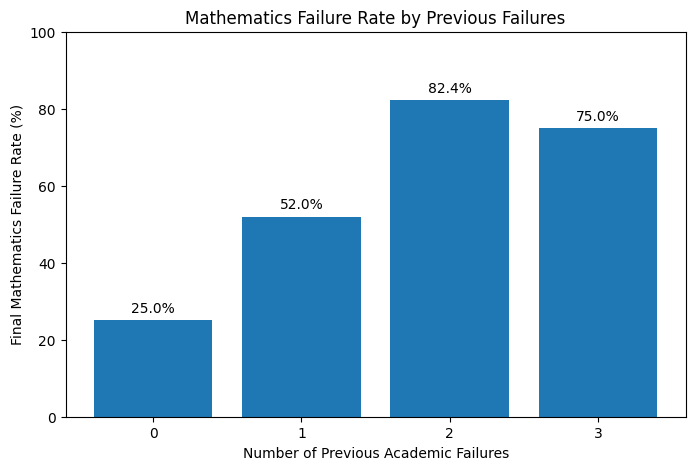

In [85]:
import matplotlib.pyplot as plt

failure_rates = (
    df.groupby("failures")["pass"]
    .apply(lambda x: (x == 0).mean() * 100)
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    failure_rates.index,
    failure_rates.values
)

plt.title("Mathematics Failure Rate by Previous Failures")
plt.xlabel("Number of Previous Academic Failures")
plt.ylabel("Final Mathematics Failure Rate (%)")
plt.xticks([0, 1, 2, 3])
plt.ylim(0, 100)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.show()

## 5. Key Findings and Visualisations

This section presents the main findings from the exploratory analysis and predictive modelling experiments.

### 5.1 Previous Academic Failures and Mathematics Performance

Previous academic failures showed a clear association with final mathematics outcomes.

Students with no previous academic failures had a final mathematics failure rate of 25%, compared with 52% for students with one previous failure and 82.4% for students with two previous failures.

These findings suggest that academic history may be useful for identifying students who could benefit from additional support.

However, the groups with two and three previous failures contained relatively few students, making their estimated failure rates less precise.

The relationship is observational and should not be interpreted as evidence that previous failures directly cause future academic failure.

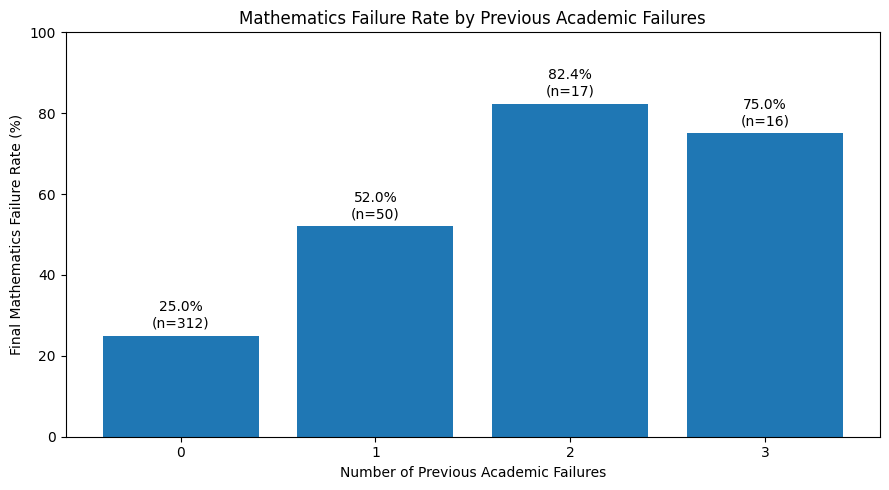

In [86]:
import matplotlib.pyplot as plt

summary = df.groupby("failures").agg(
    failure_rate=("pass", lambda x: (x == 0).mean() * 100),
    students=("pass", "count")
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    summary.index,
    summary["failure_rate"]
)

plt.title("Mathematics Failure Rate by Previous Academic Failures")
plt.xlabel("Number of Previous Academic Failures")
plt.ylabel("Final Mathematics Failure Rate (%)")
plt.xticks([0, 1, 2, 3])
plt.ylim(0, 100)

for bar, n in zip(bars, summary["students"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{bar.get_height():.1f}%\n(n={n})",
        ha="center"
    )

plt.tight_layout()
plt.show()

### 5.2 Early-Warning vs Later-Stage Prediction

One of the main objectives of this project was to investigate whether students at risk of failing mathematics could be identified before their examination grades became available.

Two approaches were compared:

- **Early-warning model:** Used previous academic failures and frequency of going out.
- **Later-stage model:** Used second-period mathematics grades (G2).

The early-warning model identified 38.5% of failing students in its test sample, while the G2-based model identified 96.2%.

This demonstrates the substantial predictive value of students' existing academic performance.

However, G2 becomes available later in the academic year, potentially reducing the time available for early intervention.

**Key finding:** There is a trade-off between how early a prediction can be made and how accurately students at risk can be identified.

**Limitation:** The models were evaluated using different train-test splits and decision thresholds. Therefore, this comparison illustrates the difference in observed performance rather than establishing a controlled comparison of the two approaches. Recall alone also does not account for false alarms.

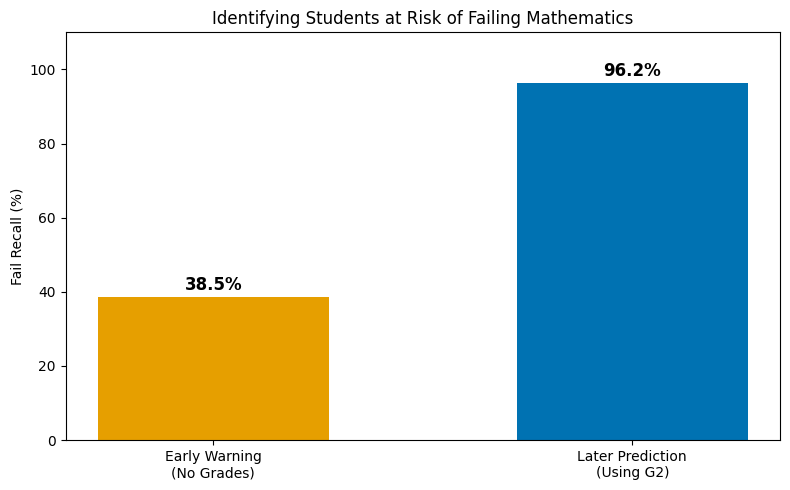

In [87]:
import matplotlib.pyplot as plt

models = ["Early Warning\n(No Grades)", "Later Prediction\n(Using G2)"]
recall = [38.5, 96.2]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    models,
    recall,
    color=["#E69F00", "#0072B2"],
    width=0.55
)

plt.title("Identifying Students at Risk of Failing Mathematics")
plt.ylabel("Fail Recall (%)")
plt.ylim(0, 110)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

### 5.3 Evaluating Early-Warning Model Errors

The confusion matrix provides a detailed breakdown of the simplified early-warning model's predictions on 79 students.

**Results:**

- **10 students:** Correctly predicted to fail.
- **16 students:** Incorrectly predicted to pass.
- **12 students:** Incorrectly predicted to fail.
- **41 students:** Correctly predicted to pass.

The model achieved:

- **Accuracy:** 64.6%
- **Failure recall:** 38.5%
- **Failure precision:** 45.5%
- **ROC-AUC:** 0.649

### Interpretation

The model successfully identified 10 of the 26 students who ultimately failed mathematics. However, it missed 16 failing students and incorrectly flagged 12 passing students.

These results highlight an important limitation of early-warning predictions based solely on student background characteristics.

Although the model identifies some students at risk, its relatively low recall means that many struggling students would not be identified.

**Practical implication:** This model should not be used as a standalone system for determining which students receive academic support. Instead, its findings could inform further investigation alongside teacher assessments, ongoing academic performance and other relevant information.

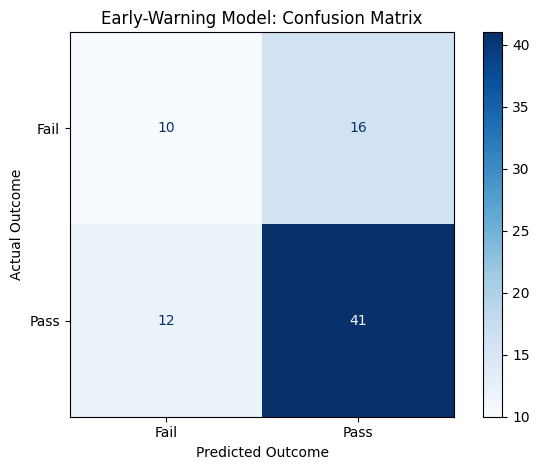

In [88]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_early,
    predictions,
    labels=[0, 1],
    display_labels=["Fail", "Pass"],
    cmap="Blues",
    values_format="d"
)

plt.title("Early-Warning Model: Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.tight_layout()
plt.show()

## 6. Conclusions and Recommendations

### 6.1 Key Findings

This project investigated student mathematics performance and evaluated the potential of machine learning models to identify students at risk of academic failure.

The analysis produced five key findings:

1. **Previous academic performance is an important predictor.** Students with a history of academic failures were more likely to fail their final mathematics examination.

2. **Early-warning predictions remain challenging.** Models using student background characteristics demonstrated limited predictive performance, with the selected simplified model achieving a test ROC-AUC of 0.649.

3. **Later academic grades substantially improve predictions.** A model using second-period mathematics grades (G2) identified 96.2% of failing students in its test sample, compared with 38.5% for the simplified early-warning model.

4. **More complex models did not consistently improve performance.** Random forest classification performed similarly to logistic regression, while a simpler two-predictor model achieved the highest exploratory repeated cross-validation ROC-AUC of 0.713.

5. **Model evaluation requires more than accuracy.** Confusion matrices, recall, precision and ROC-AUC revealed important limitations that would have been overlooked by examining accuracy alone.

### 6.2 Practical Recommendations

Based on these findings, schools could consider:

- Monitoring students with a history of academic difficulties and offering proactive academic support.
- Using regular formative assessments to identify emerging learning difficulties throughout the academic year.
- Combining quantitative indicators with teacher observations and individual student circumstances.
- Evaluating the effectiveness of interventions rather than assuming that predictive risk scores automatically improve student outcomes.

### 6.3 Limitations

Several limitations should be considered:

- The dataset contains only 395 students from a specific educational context in Portugal, limiting generalisability.
- Some student characteristics may be self-reported and subject to measurement error.
- Observed associations do not establish causal relationships.
- The early-warning models showed limited ability to identify students who eventually failed.
- Feature selection and model development involved repeated exploration of the same dataset, meaning reported performance estimates may be optimistic.
- Some predictors, such as parental education, may reflect socioeconomic inequalities and require careful consideration of fairness.
- The models were not externally validated or tested in a real school environment.

### 6.4 Final Conclusion

This analysis demonstrates that academic history and ongoing assessment results contain useful information about student performance.

However, accurately predicting academic failure before examination grades become available remains challenging.

The project highlights the importance of exploratory data analysis, interpretable machine learning, careful model validation and responsible